# Comparar modelos con puntuación consistente: FZ0, Diebold-Mariano y el conjunto de confianza de modelos en cinco ventanas de tensión

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 03 y 04 de este tema (las pruebas retrospectivas que deciden la elegibilidad)
- **Tiempo de lectura:** unos 45 minutos

**Pregunta:** Entre los modelos que pasan las compuertas de elegibilidad, ¿cuál pronostica mejor el VaR y la ES en una ventana de tensión, y se puede distinguir a ese campeón de los demás?

## Objetivos

Al terminar este notebook puedes:

- decir por qué el VaR y la ES deben puntuarse juntos, y escribir y calcular la pérdida FZ0 con la función del motor;
- mostrar con un experimento de escala qué significa que una regla de puntuación sea consistente, y leer el resultado para tres modelos;
- comparar dos modelos con la prueba de Diebold-Mariano, decir qué significa su signo, y encontrar qué modelos superan al campeón en FZ0 y en la pérdida de cuantil;
- recalcular el conjunto de confianza de modelos de las dos ventanas que versionan sus retornos, leer las otras tres, y decir por qué no se pueden recalcular;
- enunciar la regla del campeón (elegibilidad por las pruebas retrospectivas tradicionales y luego orden por FZ0) y aplicarla a las cinco ventanas de tensión.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 arch==8.0.0 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con
# notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "arch", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
arch 8.0.0
pandas 3.0.6


## Datos

Se leen cinco ventanas del caso C11, una por tensión de mercado: `equity-2007-09` (la crisis financiera), `equity-2020` (la caída por la pandemia), `rates-2022` (el ciclo de alzas), `fx-2008` (el euro frente al dólar) y `mixed-2023` (la turbulencia bancaria). Cada una guarda, para 17 modelos y dos niveles de cola, las trayectorias de VaR y ES, la FZ0 media y la pérdida de tick media, el veredicto de elegibilidad y un bloque `comparison` con el campeón, las filas de Diebold-Mariano frente a él y el conjunto de confianza de modelos.

Solo `rates-2022` y `fx-2008` versionan las pérdidas realizadas (sus fuentes son `mirror-allowed`); las otras tres guardan retornos solo derivados. Los puntajes de esas dos ventanas se recalculan entonces aquí desde los arreglos, y las otras tres se leen de las filas versionadas. La celda siguiente carga los archivos y la función auxiliar que reúne los pronósticos y los puntajes de una ventana.

In [2]:
# Cargar las cinco ventanas del caso C11 y definir el lector que reúne los pronósticos de una ventana para
# un nivel de cola
ROOT = Path("../../..").resolve()
NAMES = ("equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
C11 = ROOT / "data" / "derived" / "C11"
docs = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in NAMES}
STATUS = {"included": "versionadas", "withheld-derived-only": "retenidas"}


def forecasts_of(window, alpha):
    """Por modelo: VaR y ES en la convención de retornos (ES None sin una) y el veredicto de elegibilidad."""
    out = {}
    for model in docs[window]["outputs"]["models"]:
        level = [lv for lv in model["by_level"] if lv["alpha"] == alpha][0]
        es = None if level["es_status"] != "forecast" else -np.array(level["es"])
        out[model["model_id"]] = (-np.array(level["var"]), es, model["eligible"])
    return out


for w in NAMES:
    out = docs[w]["outputs"]
    status = STATUS[out["grid"]["realised_loss"]["status"]]
    print(f"{w:15s} {out['window']['n_forecast_days']:4d} días | pérdidas realizadas {status:11s} | "
          f"modelos elegibles {int(docs[w]['impact']['eligible_models']['value'])}")

equity-2007-09   504 días | pérdidas realizadas retenidas   | modelos elegibles 0
equity-2020      104 días | pérdidas realizadas retenidas   | modelos elegibles 4
rates-2022       249 días | pérdidas realizadas versionadas | modelos elegibles 4
fx-2008          251 días | pérdidas realizadas versionadas | modelos elegibles 10
mixed-2023        64 días | pérdidas realizadas retenidas   | modelos elegibles 17


## Método

### Paso 1: puntuar VaR y ES juntos, la pérdida FZ0

Una regla de puntuación es **consistente** para un estadístico si informar el estadístico verdadero minimiza la puntuación esperada, de modo que se premia al pronosticador por ser honesto. El VaR es elicitable: la pérdida de cuantil (pinball) $(\alpha - \mathbb 1\{y < v\})(y - v)$ es consistente para él. La ES no es elicitable por sí sola (Gneiting, 2011), pero el **par** (VaR, ES) sí lo es (Fissler y Ziegel, 2016), así que existen pérdidas que premian a un pronosticador por el VaR correcto y la ES correcta a la vez. Patton, Ziegel y Chen (2019) escogen aquella cuyas diferencias de pérdida son homogéneas de grado cero, libres de parámetros de ajuste, la pérdida FZ0. En la convención de retornos, con $y$ el retorno realizado, $v < 0$ el VaR, $e \le v$ la ES:

$$L_{FZ0}(y, v, e; \alpha) = -\frac{1}{\alpha\,e}\,\mathbb 1\{y \le v\}\,(v - y) + \frac{v}{e} + \ln(-e) - 1$$

La pérdida puede ser negativa y solo las **diferencias** entre modelos tienen sentido. `fz0_loss(y, v, e, alpha)` del motor la da día a día, `tick_loss` la pérdida pinball y `mean_scores` los promedios. La celda escribe la pérdida a mano para un modelo y muestra sus dos partes, llama al motor sobre el mismo pronóstico, y luego calcula el FZ0 medio de cada modelo con ES en `fx-2008` al 2,5 por ciento para la figura.

ewma: FZ0 medio a mano -3.706963 | motor -3.706963
FZ0 en un día sin excepción: -3.9515 | en los 8 días de excepción: 3.7209


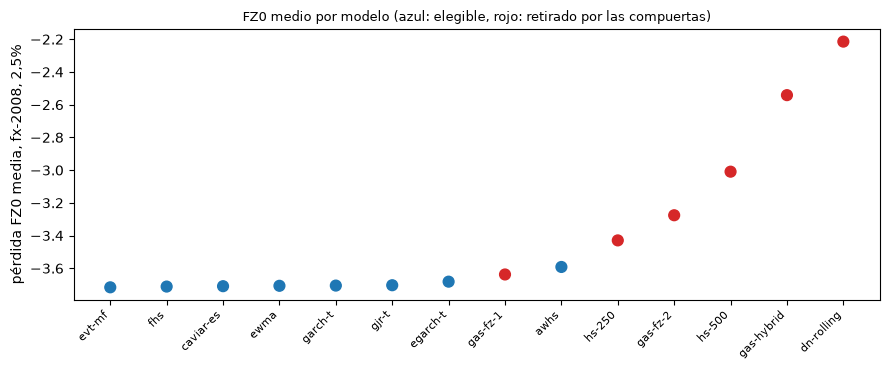

In [3]:
# FZ0 a mano para ewma al 2,5% frente al motor, y el FZ0 medio de cada modelo con ES, dibujado según su
# elegibilidad
from riskvalidation.market.scoring import fz0_loss, mean_scores, tick_loss

returns = -np.array(docs["fx-2008"]["outputs"]["grid"]["realised_loss"]["loss"])
alpha = 0.025
book = forecasts_of("fx-2008", alpha)
v, e, _ = book["ewma"]
hit = returns <= v
by_hand = -(1.0 / (alpha * e)) * hit * (v - returns) + v / e + np.log(-e) - 1.0
print(f"ewma: FZ0 medio a mano {by_hand.mean():.6f} | motor {fz0_loss(returns, v, e, alpha).mean():.6f}")
print(f"FZ0 en un día sin excepción: {by_hand[~hit].mean():.4f} | "
      f"en los {int(hit.sum())} días de excepción: {by_hand[hit].mean():.4f}")

means = {m: mean_scores(returns, vm, em, alpha).fz0_mean for m, (vm, em, _) in book.items() if em is not None}
ranked = sorted(means, key=means.get)
colour = ["tab:blue" if book[m][2] else "tab:red" for m in ranked]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(range(len(ranked)), [means[m] for m in ranked], c=colour, s=60)
ax.set_xticks(range(len(ranked)), ranked, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("pérdida FZ0 media, fx-2008, 2,5%")
ax.set_title("FZ0 medio por modelo (azul: elegible, rojo: retirado por las compuertas)", fontsize=9)
fig.tight_layout()
plt.show()

La pérdida FZ0 de `ewma` es -3,9515 en un día sin excepción y +3,7209 en los 8 días de excepción: el término de excepción es lo que la puntuación castiga, y el promedio del motor (-3,706963) es el escrito a mano. En la figura los siete puntos azules de la izquierda son los modelos elegibles con el menor FZ0 medio, agrupados a pocas centésimas entre sí en torno a -3,7, de modo que la puntuación sola apenas los separa. Un punto rojo es mejor que uno azul: `gas-fz-1`, que las compuertas retiraron, puntúa bajo el elegible `awhs`. Por eso el orden viene después de la elegibilidad y no en su lugar. La figura muestra solo la pérdida media; si una diferencia de pocas centésimas es más que suerte lo decide la prueba de Diebold-Mariano del paso 3.

### Paso 2: qué significa la consistencia, mostrado escalando un pronóstico

Si el puntaje es consistente, un pronóstico demasiado pequeño debe puntuar peor que uno mejor, y la **mejor escala** del pronóstico de un modelo dice a qué distancia está de su propio óptimo. La celda multiplica el VaR y la ES de tres modelos en `fx-2008` al 2,5 por ciento por un factor $k$ de 0,6 a 1,8 y calcula la FZ0 media de cada pronóstico escalado. El factor en que la curva es más baja es el que prefieren los retornos realizados: cerca de 1 significa que el pronóstico ya era el mejor de su familia escalada; muy por encima de 1 significa que fue demasiado pequeño para lo ocurrido.

ewma    k = 1: FZ0 medio -3.7070 | mejor factor 1.05: -3.7114
evt-mf  k = 1: FZ0 medio -3.7162 | mejor factor 1.00: -3.7162
hs-250  k = 1: FZ0 medio -3.4294 | mejor factor 1.40: -3.6350


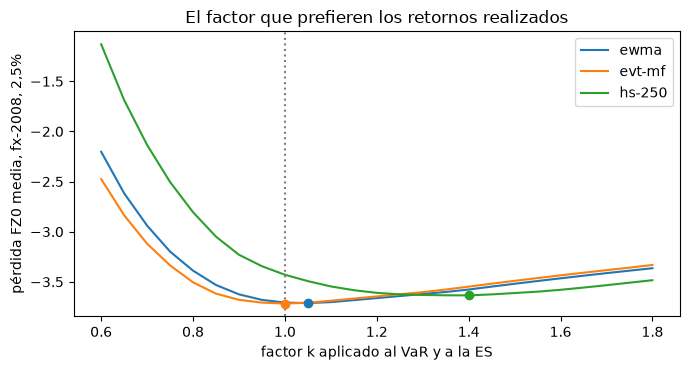

In [4]:
# FZ0 medio del VaR y la ES de tres modelos multiplicados por un factor k, y el factor que prefiere cada modelo
factors = np.linspace(0.6, 1.8, 25)
curves = {}
for model_id in ("ewma", "evt-mf", "hs-250"):
    v, e, _ = book[model_id]
    curves[model_id] = np.array([fz0_loss(returns, k * v, k * e, 0.025).mean() for k in factors])
    best = int(np.argmin(curves[model_id]))
    print(f"{model_id:7s} k = 1: FZ0 medio {fz0_loss(returns, v, e, 0.025).mean():.4f} | "
          f"mejor factor {factors[best]:.2f}: {curves[model_id][best]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
for model_id, curve in curves.items():
    ax.plot(factors, curve, label=model_id)
    ax.scatter(factors[int(np.argmin(curve))], curve.min(), zorder=3)
ax.axvline(1.0, color="grey", linestyle=":")
ax.set_xlabel("factor k aplicado al VaR y a la ES")
ax.set_ylabel("pérdida FZ0 media, fx-2008, 2,5%")
ax.set_title("El factor que prefieren los retornos realizados")
ax.legend()
fig.tight_layout()
plt.show()

Cada curva es el FZ0 medio de un modelo cuando su VaR y su ES se multiplican por $k$, y el punto marca el factor que prefirieron los retornos realizados. Para `evt-mf` el punto más bajo está en $k = 1{,}00$ (-3,7162): su pronóstico ya era el mejor de su familia escalada. Para `ewma` está en 1,05 (-3,7114 frente a -3,7070 sin escalar). Para `hs-250` está en 1,40 (-3,6350 frente a -3,4294): en la crisis de 2008 el pronóstico histórico habría necesitado números 40 por ciento mayores para puntuar mejor en su familia, y la puntuación lo dice con una brecha de cerca de 0,21. El experimento muestra que FZ0 premia el tamaño correcto y no solo el orden correcto de los días; no dice que escalar un pronóstico por 1,40 habría sido un buen modelo, solo dónde está la pérdida más baja en una ventana.

### Paso 3: Diebold-Mariano frente al campeón

Para decir que un modelo es mejor que otro, y no solo afortunado en esta ventana, Diebold y Mariano (1995) prueban si la media del diferencial de pérdida $d_t = L_t^{A} - L_t^{B}$ es cero:

$$DM = \frac{\bar d}{\sqrt{\widehat{\mathrm{LRV}}/T}} \xrightarrow{d} N(0,1), \qquad \widehat{\mathrm{LRV}} = \hat\gamma_0 + 2\sum_{j=1}^{h}\left(1 - \tfrac{j}{h+1}\right)\hat\gamma_j$$

con $\hat\gamma_j$ las autocovarianzas muestrales de $d_t$ y $h$ los rezagos de Bartlett; para pronósticos a un paso $h = 0$. Un $\bar d$ **negativo** significa que el modelo A tiene la menor pérdida, así que es mejor. `diebold_mariano(loss_a, loss_b, lags)` del motor devuelve la diferencia media, el estadístico y el valor p normal de dos colas. La celda elige al campeón con la regla del paso 5 (el menor FZ0 medio entre los modelos elegibles que tienen ES), compara a cada otro modelo con él en FZ0 en `fx-2008` y `rates-2022` en los dos niveles, y dibuja los estadísticos de `fx-2008` al 2,5 por ciento.

fx-2008     alfa 0.010 | campeón caviar-es | significativamente mejores 0 | peores 5 de 13
fx-2008     alfa 0.025 | campeón evt-mf | significativamente mejores 0 | peores 4 de 13
rates-2022  alfa 0.010 | campeón ewma | significativamente mejores 0 | peores 4 de 13
rates-2022  alfa 0.025 | campeón ewma | significativamente mejores 0 | peores 2 de 13


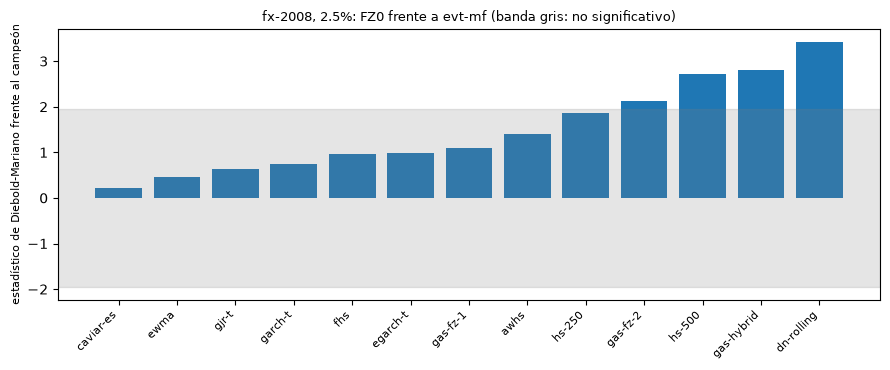

In [5]:
# El campeón según la regla del paso 5 y Diebold-Mariano de cada otro modelo frente a él en FZ0, en los dos
# niveles
from riskvalidation.market.scoring import diebold_mariano

dm = {}
for window in ("fx-2008", "rates-2022"):
    y = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    for alpha in (0.01, 0.025):
        book = forecasts_of(window, alpha)
        fz = {m: fz0_loss(y, vm, em, alpha) for m, (vm, em, _) in book.items() if em is not None}
        champion = min((m for m in fz if book[m][2]), key=lambda m: fz[m].mean())
        results = {m: diebold_mariano(fz[m], fz[champion], 0) for m in fz if m != champion}
        dm[(window, alpha)] = (champion, results)
        better = sum(r.p_value < 0.05 and r.mean_diff < 0 for r in results.values())
        worse = sum(r.p_value < 0.05 and r.mean_diff > 0 for r in results.values())
        print(f"{window:11s} alfa {alpha:5.3f} | campeón {champion} | "
              f"significativamente mejores {better} | peores {worse} de {len(results)}")

champion, results = dm[("fx-2008", 0.025)]
names = sorted(results, key=lambda m: results[m].statistic)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(names)), [results[m].statistic for m in names], color="tab:blue")
ax.axhspan(-1.96, 1.96, color="grey", alpha=0.2)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("estadístico de Diebold-Mariano frente al campeón", fontsize=8)
ax.set_title(f"fx-2008, 2.5%: FZ0 frente a {champion} (banda gris: no significativo)", fontsize=9)
fig.tight_layout()
plt.show()

En `fx-2008` al 2,5 por ciento todos los modelos tienen un estadístico positivo, es decir, una pérdida mayor que la del campeón `evt-mf`, pero solo cuatro de los 13 cruzan la banda gris de 1,96: `gas-fz-2`, `hs-500`, `gas-hybrid` y `dn-rolling`. EWMA, la familia GARCH, `fhs` y `caviar-es` no se distinguen del campeón, y `hs-250` queda justo dentro de la banda. Los conteos impresos dicen lo mismo en los cuatro casos: ningún modelo es significativamente mejor que el campeón, y entre 2 y 5 de los 13 son significativamente peores. La figura muestra que un campeón elegido por la menor media es un orden, no una prueba de superioridad: con 251 días la mayor parte de la escalera está estadísticamente a su nivel.

La pérdida FZ0 puntúa el VaR y la ES juntos; la pérdida de cuantil puntúa solo el VaR, así que un orden por pérdida de cuantil puede diferir del de FZ0, sobre todo en un escalón que no tiene ES. La celda siguiente toma al campeón de FZ0 de `rates-2022` al 1 por ciento y pregunta qué modelos lo superan en la pérdida de cuantil con `tick_loss` y `diebold_mariano`.

In [6]:
# La pérdida de cuantil (solo VaR) de cada modelo en rates-2022 al 1%, comparada con el campeón de FZ0 por
# Diebold-Mariano
y = -np.array(docs["rates-2022"]["outputs"]["grid"]["realised_loss"]["loss"])
book = forecasts_of("rates-2022", 0.01)
champion, fz_results = dm[("rates-2022", 0.01)]
tick = {m: tick_loss(y, vm, 0.01) for m, (vm, em, _) in book.items()}
winners = {}
for model_id in tick:
    if model_id != champion:
        result = diebold_mariano(tick[model_id], tick[champion], 0)
        if result.p_value < 0.05 and result.mean_diff < 0:
            winners[model_id] = (result.p_value, book[model_id][1] is not None, book[model_id][2])
print(f"campeón de FZ0: {champion}")
print(f"modelos significativamente mejores en la pérdida de cuantil: {len(winners)}")
for model_id, (p_value, has_es, eligible) in winners.items():
    print(f"  {model_id}: p {p_value:.4f} | tiene ES: {'sí' if has_es else 'no'} | "
          f"elegible: {'sí' if eligible else 'no'}")

campeón de FZ0: ewma
modelos significativamente mejores en la pérdida de cuantil: 1
  cf-rolling: p 0.0438 | tiene ES: no | elegible: no


### Paso 4: el conjunto de confianza de modelos

Diebold-Mariano compara dos modelos. El conjunto de confianza de modelos de Hansen, Lunde y Nason (2011) responde la pregunta que un validador hace sobre toda una escalera: ¿qué modelos **no se distinguen del mejor**? Parte con todos los modelos, prueba la hipótesis de que tienen igual pérdida esperada, y mientras se rechaza elimina al peor modelo, usando un remuestreo para la distribución nula; los modelos que sobreviven forman el conjunto, con confianza $1-\alpha_{MCS}$. Contraste usa el estadístico de rango ($T_R$), 90 por ciento de confianza, un remuestreo estacionario de 1.000 sorteos con bloques de 10 días y la pérdida FZ0. Un modelo está en el conjunto cuando su valor p de MCS es al menos 0,10. El motor lo calcula con `arch.bootstrap.MCS` (el extra opcional `market`, instalado en este entorno con `pandas`), con semilla: las mismas pérdidas y la misma semilla dan los mismos valores p. Dos ventanas versionan sus retornos realizados, `rates-2022` y `fx-2008`, así que la celda recalcula sus conjuntos en los dos niveles desde los pronósticos con los ajustes que registra el artefacto; las otras tres ventanas tienen retornos solo derivados, de modo que sus conjuntos se leen, no se recalculan. La figura dibuja los valores p de MCS de `fx-2008` al 1 por ciento.

rates-2022  alfa 0.010 | conjunto 14 de 14
rates-2022  alfa 0.025 | conjunto 12 de 14
fx-2008     alfa 0.010 | conjunto 13 de 14
fx-2008     alfa 0.025 | conjunto 13 de 14
equity-2007-09  conjunto al 1% (leído): 12 de 14
equity-2020     conjunto al 1% (leído): 14 de 14
mixed-2023      conjunto al 1% (leído): 2 de 14


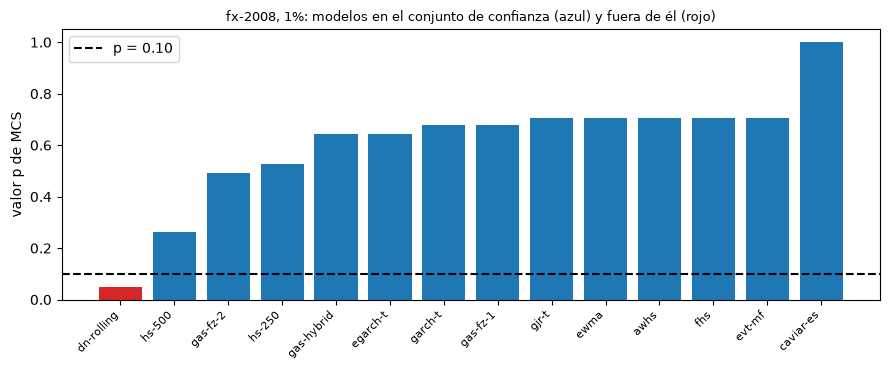

In [7]:
# Recalcular el conjunto de confianza de las dos ventanas que versionan retornos, leer las otras tres,
# dibujar fx-2008 al 1%
from riskvalidation.market.scoring import model_confidence_set

sets = {}
for window in ("rates-2022", "fx-2008"):
    y = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    for alpha in (0.01, 0.025):
        setting = [m for m in docs[window]["outputs"]["comparison"]["mcs"] if m["alpha"] == alpha][0]
        ids = [m["model_id"] for m in setting["members"]]
        book = forecasts_of(window, alpha)
        losses = np.column_stack([fz0_loss(y, book[i][0], book[i][1], alpha) for i in ids])
        args = (setting["confidence"], setting["statistic"], setting["n_bootstrap"], setting["block_length"], 42)
        sets[(window, alpha)] = (ids, model_confidence_set(losses, *args))
        print(f"{window:11s} alfa {alpha:5.3f} | conjunto {len(sets[(window, alpha)][1].members)} de {len(ids)}")
for window in ("equity-2007-09", "equity-2020", "mixed-2023"):
    mcs = [m for m in docs[window]["outputs"]["comparison"]["mcs"] if m["alpha"] == 0.01][0]
    print(f"{window:15s} conjunto al 1% (leído): {mcs['n_in_set']} de {len(mcs['members'])}")

ids, fresh = sets[("fx-2008", 0.01)]
order = np.argsort(fresh.p_values)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(ids)), fresh.p_values[order], color=["tab:blue" if i in fresh.members else "tab:red" for i in order])
ax.axhline(0.10, color="black", linestyle="--", label="p = 0.10")
ax.set_xticks(range(len(ids)), [ids[i] for i in order], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("valor p de MCS")
ax.set_title("fx-2008, 1%: modelos en el conjunto de confianza (azul) y fuera de él (rojo)", fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()

Cada barra es el valor p de MCS de un modelo en `fx-2008` al 1 por ciento, y un modelo está en el conjunto cuando su barra supera la línea de trazos de 0,10. Solo `dn-rolling` (p cerca de 0,05) queda fuera del conjunto, `hs-500` es el siguiente más débil con cerca de 0,26, y `caviar-es`, el campeón, tiene p igual a 1 por construcción. Los conjuntos recalculados tienen 13 de 14 modelos en `fx-2008` en los dos niveles y 14 de 14 y 12 de 14 en `rates-2022`; los conjuntos versionados de las ventanas cuyos retornos se retienen tienen 12 de 14 en `equity-2007-09`, 14 de 14 en `equity-2020` y 2 de 14 en `mixed-2023`. Una ventana con pocos días o pocas pérdidas separa mal los modelos; `mixed-2023` los separa porque ningún modelo tiene una excepción en sus 64 días, el término indicador de FZ0 desaparece y la puntuación la decide cuán pequeña es la ES pronosticada. La figura muestra a quién no se puede excluir, no quién es el mejor.

### Paso 5: la regla del campeón

La escalera separa dos preguntas. La **elegibilidad** pregunta si un modelo es aceptable: no debe estar en rojo en Kupiec, en cobertura condicional ni en la prueba de Acerbi-Szekely en ninguno de los dos niveles (notebooks 03 y 04). El **orden** pregunta cuál modelo aceptable pronostica mejor: la FZ0 media más baja, entre los modelos elegibles que tienen ES todos los días. Es el marco de la prueba retrospectiva comparativa de Nolde y Ziegel (2017): un validador quiere saber si un retador supera al campeón, no solo si el campeón es rechazado. Una ventana puede no tener campeón: si ningún modelo elegible tiene ES todos los días no hay puntaje FZ0 que ordenar, y el documento lo dice en lugar de elegir uno. La celda lee los campeones versionados y el número de modelos elegibles en las cinco ventanas, y la FZ0 media del campeón.

window          elegibles  campeón 1%         campeón 2.5%      
equity-2007-09          0  -                  -                 
equity-2020             4  fhs -1.986         evt-mf -2.364     
rates-2022              4  ewma -3.811        ewma -4.002       
fx-2008                10  caviar-es -3.557   evt-mf -3.716     
mixed-2023             17  gjr-t -4.439       gjr-t -4.623      


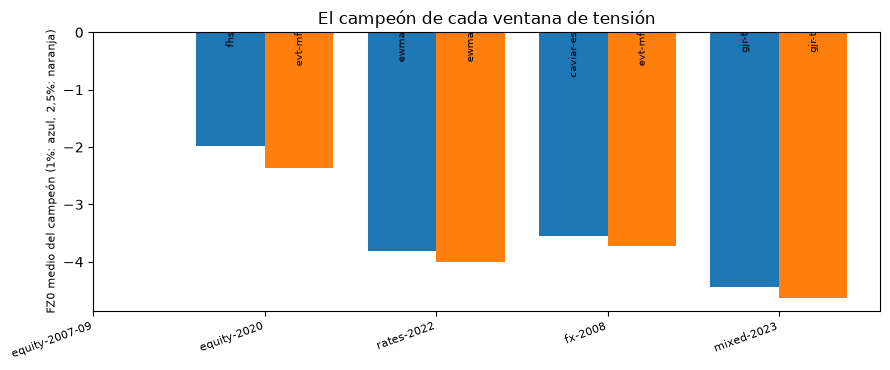

In [8]:
# Modelos elegibles, campeones y el FZ0 medio del campeón en las cinco ventanas, como se versionaron,
# dibujados en ambos niveles
fig, ax = plt.subplots(figsize=(9, 3.8))
print(f"{'window':15s} {'elegibles':>9s}  {'campeón 1%':18s} {'campeón 2.5%':18s}")
for position, window in enumerate(NAMES):
    outputs = docs[window]["outputs"]
    champions = {c["alpha"]: c["model_id"] for c in outputs["comparison"]["champions"]}
    level_of = {(m["model_id"], lv["alpha"]): lv for m in outputs["models"] for lv in m["by_level"]}
    eligible = int(docs[window]["impact"]["eligible_models"]["value"])
    scores = {a: level_of[(champions[a], a)]["fz0_mean"] if champions[a] else None for a in (0.01, 0.025)}
    cells = [f"{champions[a]} {scores[a]:.3f}" if scores[a] is not None else "-" for a in scores]
    print(f"{window:15s} {eligible:9d}  {cells[0]:18s} {cells[1]:18s}")
    for shift, alpha in ((-0.2, 0.01), (0.2, 0.025)):
        if scores[alpha] is not None:
            ax.bar(position + shift, scores[alpha], width=0.4, color="tab:blue" if alpha == 0.01 else "tab:orange")
            ax.annotate(champions[alpha], (position + shift, 0), ha="center", va="top", fontsize=7, rotation=90)
ax.set_xticks(range(len(NAMES)), NAMES, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("FZ0 medio del campeón (1%: azul, 2,5%: naranja)", fontsize=8)
ax.set_title("El campeón de cada ventana de tensión")
fig.tight_layout()
plt.show()

Cada par de barras es el FZ0 medio del campeón de una ventana al 1 por ciento (azul) y al 2,5 por ciento (naranja), rotulado con su nombre; `equity-2007-09` no tiene barras porque ningún modelo es elegible ahí y el documento lo dice en vez de elegir uno. El campeón cambia con la ventana: `fhs` y `evt-mf` en `equity-2020`, `ewma` en `rates-2022`, `caviar-es` y `evt-mf` en `fx-2008` y `gjr-t` en `mixed-2023`, y en ninguna ventana es una simulación histórica simple. Los niveles de FZ0 no son comparables entre ventanas, pues la escala de los retornos difiere, así que la figura se lee barra por barra y nunca como un orden de ventanas.

## Resultados

**Respuesta:** En `fx-2008` el campeón es `caviar-es` al 1 por ciento (FZ0 medio -3,557) y `evt-mf` en el nivel 0,025 (-3,716), pero no se distingue de la mayor parte de la escalera: ningún modelo es significativamente mejor que él, solo algunos de los otros 13 son significativamente peores (5 en el nivel 0,01, 4 en 0,025), y 13 de 14 modelos están en el conjunto de confianza. El campeón cambia además con la ventana (`fhs`, `ewma`, `caviar-es`, `gjr-t`) y nunca es una simulación histórica simple.

- **FZ0, a mano y con el motor.** Para `ewma` al 2,5 por ciento en `fx-2008` el FZ0 medio es -3,706963 a mano y con el motor. La pérdida es en promedio -3,9515 en un día sin excepción y +3,7209 en los 8 días de excepción: el término de excepción es lo que la puntuación castiga.
- **Consistencia, mostrada por escala.** Multiplicar el VaR y la ES de `evt-mf` por un factor $k$ da su FZ0 medio más bajo en $k = 1{,}00$ (-3,7162); para `ewma` en 1,05 (-3,7114 frente a -3,7070 sin escalar); para `hs-250` en 1,40 (-3,6350 frente a -3,4294 sin escalar).
- **Diebold-Mariano.** La regla da los campeones `caviar-es` y `evt-mf` en `fx-2008` y `ewma` en ambos niveles en `rates-2022`. Ningún modelo es significativamente mejor que el campeón en FZ0 en ninguno de los cuatro casos. En la pérdida de cuantil, que ve solo el VaR, un modelo supera al campeón de `rates-2022` al 1 por ciento: `cf-rolling` (p 0,0438), que no tiene ES y no es elegible.
- **El conjunto de confianza.** Los conjuntos recalculados tienen 14 de 14 modelos en `rates-2022` al 1 por ciento, 12 de 14 al 2,5 por ciento y 13 de 14 en `fx-2008` en los dos niveles. Los conjuntos versionados de las tres ventanas con retornos retenidos tienen 12 de 14 (`equity-2007-09`), 14 de 14 (`equity-2020`) y 2 de 14 (`mixed-2023`).
- **La regla del campeón en cinco ventanas.** `equity-2007-09` no tiene campeón porque ningún modelo es elegible. `equity-2020` tiene 4 modelos elegibles y campeones `fhs` (FZ0 -1,986) y `evt-mf` (-2,364). `rates-2022` tiene 4 elegibles y `ewma` en ambos niveles (-3,811, -4,002). `fx-2008` tiene 10 elegibles. `mixed-2023` tiene 17 elegibles y `gjr-t` en ambos niveles (-4,439, -4,623).

Lo que este notebook no muestra: ninguna prueba de un modelo a nivel de mesa (notebook 06) ni los modelos semiparamétricos dinámicos en detalle (notebook 07).

## Resumen

- VaR y ES se puntúan juntos porque el par es elicitable conjuntamente; la pérdida FZ0 es el miembro sin parámetros de esa clase. Su nivel no significa nada, sus diferencias entre modelos sí.
- Una puntuación consistente premia el pronóstico correcto: escalar un pronóstico muestra cuán lejos está cada modelo de su mejor escala, y un modelo que fue demasiado pequeño en una crisis prefiere un factor mayor.
- Diebold-Mariano convierte una diferencia de pérdida media en una prueba; un signo negativo significa que el primer modelo es mejor. Con el campeón fijo, la mayor parte de la escalera está estadísticamente a su nivel en FZ0, y la pérdida de cuantil puede poner sobre él a un escalón que solo tiene VaR.
- El conjunto de confianza de modelos responde otra pregunta, qué modelos no se distinguen del mejor. Tiene semilla, así que aquí se recalculan las dos ventanas que versionan sus retornos; las otras tres se leen, pues sus retornos se retienen.
- El campeón se elige en dos pasos: elegibilidad por las pruebas retrospectivas tradicionales y luego el menor FZ0 entre los modelos elegibles con ES todos los días. Una ventana puede no tener campeón, y el documento lo dice.

**Qué probar después.** Elige otra ventana y nivel en el paso 3 y encuentra un modelo significativamente peor que el campeón en FZ0 e indistinguible en pérdida de cuantil; luego continúa con el notebook 06, que pasa de los modelos a las mesas.

## Referencias

- Gneiting, T. (2011), Making and evaluating point forecasts, Journal of the American Statistical Association 106(494). https://doi.org/10.1198/jasa.2011.r10138
- Fissler, T. y Ziegel, J. F. (2016), Higher order elicitability and Osband's principle, Annals of Statistics 44(4). https://doi.org/10.1214/16-AOS1439
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Diebold, F. X. y Mariano, R. S. (1995), Comparing predictive accuracy, Journal of Business and Economic Statistics 13(3). https://doi.org/10.1080/07350015.1995.10524599
- Hansen, P. R., Lunde, A. y Nason, J. M. (2011), The model confidence set, Econometrica 79(2). https://doi.org/10.3982/ECTA5771
- Nolde, N. y Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041